# Exam

# Fit one TEC curve (Python port of `TEC_all-day_noise.pro`)

Pipeline per curve, exactly as in the IDL loop: drop NaNs → collapse constant plateaus & interpolate → shift time to start at 0 → match known flare times to samples → add a dummy flare if fewer than 3 true flares → MCMC fit with four sinusoids + flares → best-fit trend/flares and 95 % predictive band.

In [3]:
import pytensor
pytensor.config.cxx = ""   # no C compiler needed

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from tec_mcmc import SamplerConfig, fit_curve
from tec_mcmc.tec import load_tec_csv, prepare_curve

DATA = Path("../Data/tec_vert_no_SZA_20170907_El_10_90_Lat_15_60_Lon_90_90_SSA_30_90min.csv")
T_PEAKS_SOLAR = np.array([302., 454., 594., 615., 873., 876., 880., 891., 993., 1123., 1308.])
CURVE = 2055   # 0-based curve number == IDL loop index i (CSV column i+2)

In [72]:
# The CSV has no header; time is in seconds in column 0 and is converted to minutes.
curves = load_tec_csv(DATA)
print(len(curves), "curves; this one has", len(curves[CURVE][0]), "finite samples")

2380 curves; this one has 256 finite samples


In [74]:
rng = np.random.default_rng(CURVE)   # dummy-flare placement (IDL used RANDOMU)
t_abs, y_raw = curves[CURVE]
t, y, flare_idx, true_idx, t0 = prepare_curve(t_abs, y_raw, T_PEAKS_SOLAR, rng=rng)

print("true flares in window :", t[true_idx] + t0)
print("flare indices fitted  :", flare_idx, "(last one is a dummy if < 3 true flares)")

true flares in window : [993.]
flare indices fitted  : [152  37] (last one is a dummy if < 3 true flares)


In [76]:
config = SamplerConfig(
    draws=100_000, tune=100_000,   # ~3-4 min per curve; use 20_000 for quick looks
    chains=4, cores=1, sampler="demetropolisz", random_seed=42,
    n_starts=30,                   # multi-start least squares to seed the chains
)
result = fit_curve(t, y, flare_idx, config=config)

print("best-fit source :", result.map_source)
print("sigma (best fit):", round(result.sigma_map, 4))
print("log-likelihood  :", round(result.map_log_likelihood, 1))
for k, v in result.diagnostics.items():
    print(f"  {k:32s} {v:.3f}" if isinstance(v, float) else f"  {k:32s} {v}")

/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/pytensor/tensor/rewriting/elemwise.py:1004: UserWarning: Loop fusion failed because the resulting node would exceed the kernel argument limit.
  warn(
Sequential sampling (4 chains in 1 job)
DEMetropolisZ: [offset, harmonic_period, b_sin, b_cos, flare_amplitude, flare_peak_time, flare_rise_time, flare_decay_time, sigma]


/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

...

/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:1202: 
RuntimeWarning: overflow encountered in exp
  "accept": np.exp(accept),

Sampling 4 chains for 100_000 tune and 100_000 draw iterations (400_000 + 400_000 draws total) took 66 seconds.


best-fit source : mcmc
sigma (best fit): 0.018
log-likelihood  : 665.9
  rhat_curves_max                  1.796
  ess_curves_min                   289.937
  rhat_params_max                  2.799
  ess_params_min                   229.387
  trend_chain_spread_over_sigma    0.917
  flares_chain_spread_over_sigma   0.615
  model_chain_spread_over_sigma    0.723
  converged                        False


**Reading the diagnostics.**

* `rhat_params_max` – R-hat over the individual parameters. Expect it to stay well above 1: several different sets of four sinusoids describe the same smooth 2-hour trend, and two nearby-period sinusoids with large opposite amplitudes can cancel, so single parameters are not identifiable.
* `rhat_curves_max`, `ess_curves_min` – the same statistics for the quantities actually used: the trend, the summed flares and the full model on a 25-point time grid, plus `sigma`. `converged` is `True` when R-hat < 1.05 and ESS > 100 for all of these.
* `*_chain_spread_over_sigma` – the largest gap between the four chains' mean curves, in units of the noise sigma. A `model_chain_spread_over_sigma` well below 1 means the fitted curve agrees across chains to a fraction of the noise. When the trend and flare spreads are larger than the model spread, the trend/flare *split* is uncertain: the sinusoids can absorb part of a flare. That is real posterior uncertainty, not a sampler bug.

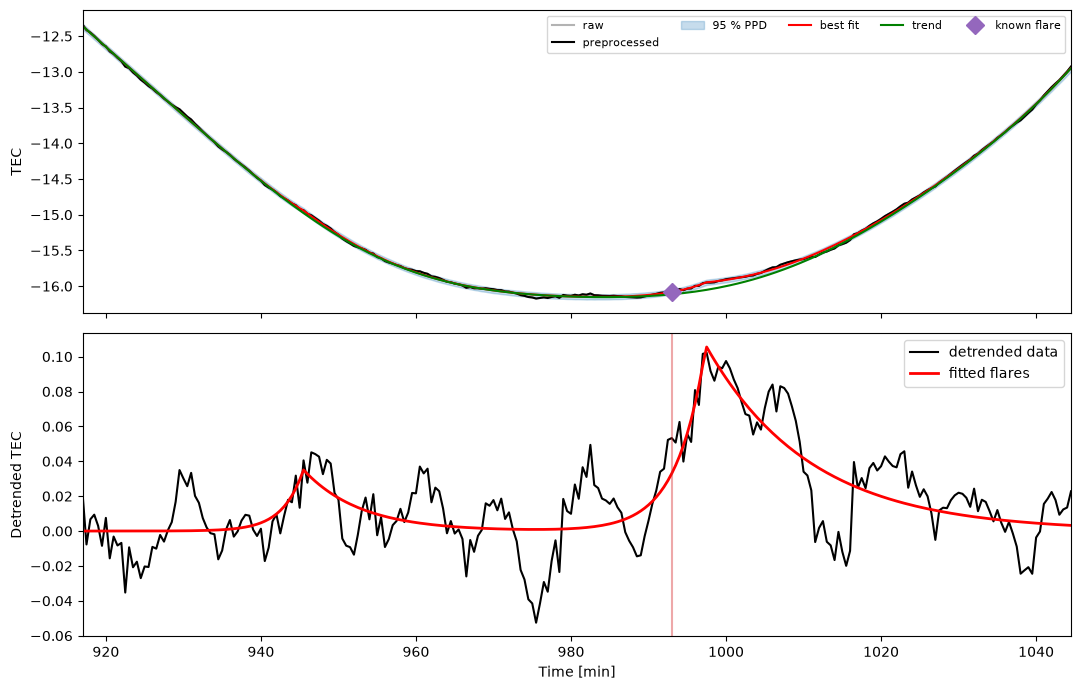

In [78]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(t_abs, y_raw, color="0.7", label="raw")
ax[0].plot(t + t0, y, "k", label="preprocessed")
ax[0].fill_between(t + t0, result.ppd_lower, result.ppd_upper, color="C0", alpha=0.25, label="95 % PPD")
ax[0].plot(t + t0, result.map_model, "r", label="best fit")
ax[0].plot(t + t0, result.map_trend, "g", label="trend")
ax[0].plot((t + t0)[true_idx], result.map_model[true_idx], "D", color="C4", ms=9, label="known flare")
ax[0].set_ylabel("TEC"); ax[0].legend(ncol=5, fontsize=8)
ax[1].plot(t + t0, y - result.map_trend, "k", label="detrended data")
ax[1].plot(t + t0, result.map_flares, "r", lw=2, label="fitted flares")
for tp in T_PEAKS_SOLAR:
    ax[1].axvline(tp, color="C3", alpha=0.4)
ax[1].set_xlim(t_abs.min(), t_abs.max())
ax[1].set_xlabel("Time [min]"); ax[1].set_ylabel("Detrended TEC"); ax[1].legend()
fig.tight_layout()

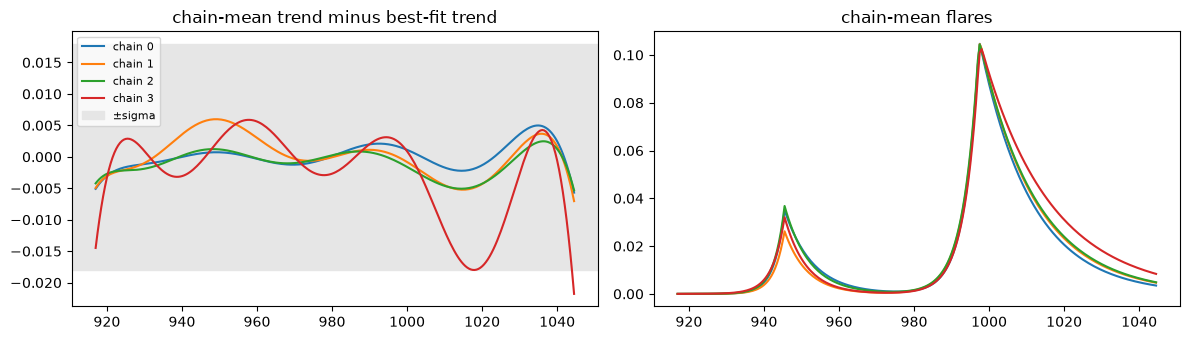

In [79]:
# Do the chains agree?  Mean trend / flares per chain (posterior rows are chain-major).
from tec_mcmc.models import split_model_components
S = result.posterior_samples.reshape(config.chains, -1, result.posterior_samples.shape[1])
n_model = S.shape[2] - 1
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
for c in range(config.chains):
    rows = S[c, :: max(1, S.shape[1] // 500)]
    comps = np.array([split_model_components(t, r[:n_model], result.n_flares) for r in rows])
    ax[0].plot(t + t0, comps[:, 0].mean(0) - result.map_trend, label=f"chain {c}")
    ax[1].plot(t + t0, comps[:, 1].mean(0), label=f"chain {c}")
ax[0].axhspan(-result.sigma_map, result.sigma_map, color="0.9", label="±sigma")
ax[0].set_title("chain-mean trend minus best-fit trend"); ax[1].set_title("chain-mean flares")
ax[0].legend(fontsize=8); fig.tight_layout()

In [93]:
# Posterior summary of the physical parameters (columns follow the IDL/SoBAT order)
from tec_mcmc.models import unpack_parameter_matrix
u = unpack_parameter_matrix(result.posterior_samples, result.n_flares)
for k, v in u.items():
    print(f"{k:20s} median", np.round(np.median(v, axis=0), 3))

offset               median -1.477
harmonic_amplitude   median [ 0.057  0.345  9.634 21.737]
harmonic_period      median [ 50.301 117.6   341.154 477.457]
harmonic_phase       median [ 0.029  2.747  1.393 -1.984]
sigma                median 0.018
flare_amplitude      median [0.106 0.034]
flare_peak_time      median [80.427 28.498]
flare_rise_time      median [3.912 2.836]
flare_decay_time     median [14.767  6.15 ]


In [95]:
result.map_params

array([ 6.39507875e+00,  6.01119267e-02,  5.07816724e+01,  1.32334095e-01,
        2.95499571e-01,  1.11254272e+02,  2.45150175e+00,  1.58566091e+01,
        3.37629068e+02,  8.37320167e-01,  3.77387064e+01,  4.74745708e+02,
       -2.19011551e+00,  1.06155981e-01,  8.04170589e+01,  3.77609011e+00,
        1.34914651e+01,  3.50655088e-02,  2.84953321e+01,  2.73633418e+00,
        7.34411732e+00,  1.79607667e-02])

In [97]:
result.sigma_map

0.017960766743380124

## Fit all the curves

In [22]:
import os
import time

# Must be set before pytensor is imported; worker processes inherit them.
os.environ.setdefault("PYTENSOR_FLAGS", "cxx=")  # same as pytensor.config.cxx = "" in the notebooks
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(_v, "1")

import json
import time
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import numpy as np

from tec_mcmc import SamplerConfig, fit_curve, fit_one, save
from tec_mcmc.tec import load_tec_csv, prepare_curve

CSV_PATH = Path("../Data/tec_vert_no_SZA_20170907_El_10_90_Lat_15_60_Lon_90_90_SSA_30_90min.csv")
OUT_JSON = Path("tec_mcmc_results/map_params.json")
T_PEAKS_SOLAR = np.array([302., 454., 594., 615., 873., 876., 880., 891., 993., 1123., 1308.])

MAX_WORKERS = 1      # number of performance cores
CURVES = 4        # None = all curves; e.g. range(8) for a timing test
SAVE_EVERY = 10      # rewrite the JSON after this many new results

CONFIG = SamplerConfig(
    draws=100_000, tune=100_000, chains=4, cores=1,
    sampler="demetropolisz", random_seed=42, n_starts=30,
    progressbar=False,
)


def main():
    OUT_JSON.parent.mkdir(parents=True, exist_ok=True)
    results = json.loads(OUT_JSON.read_text()) if OUT_JSON.exists() else {}

    curves = load_tec_csv(CSV_PATH)
    ids = range(len(curves)) if CURVES is None else range(CURVES)

    jobs, meta = [], {}
    for i in ids:
        if f"flare_{i}" in results:
            continue
        t_abs, y_raw = curves[i]
        rng = np.random.default_rng(i)   # dummy-flare placement, as in the notebooks
        t, y, flare_idx, _true_idx, t0 = prepare_curve(t_abs, y_raw, T_PEAKS_SOLAR, rng=rng)
        jobs.append((i, t, y, flare_idx))
        meta[i] = {
            "t_0": t0,
            "t": t.tolist(),
            "y_raw": np.asarray(y_raw, float).tolist(),
            "flare_indices": np.asarray(flare_idx, int).tolist(),
            "true_indices": np.asarray(_true_idx, int).tolist(),
            "has_dummy": len(flare_idx) > len(_true_idx),
        }
    print(f"{len(jobs)} curves to fit, {len(results)} already done")

    start, unsaved = time.time(), 0
    with ProcessPoolExecutor(max_workers=MAX_WORKERS) as pool:
        futures = {pool.submit(fit_one, *job, CONFIG): job[0] for job in jobs}
        for n, fut in enumerate(as_completed(futures), 1):
            i = futures[fut]
            try:
                _, params = fut.result()
            except Exception as exc:   # one bad curve must not stop the run
                print(f"curve {i} failed: {exc!r}")
                continue
            results[f"flare_{i}"] = {**meta[i], "map_params": params}
            unsaved += 1
            if unsaved >= SAVE_EVERY:
                save(results)
                unsaved = 0
            elapsed = time.time() - start
            print(f"[{n}/{len(jobs)}] curve {i} done, "
                  f"~{elapsed / n * (len(jobs) - n) / 60:.0f} min left")
    save(results, OUT_JSON)
    print(f"saved {len(results)} curves to {OUT_JSON}")


start = time.time()

main()

end = time.time()
print(end - start)

4 curves to fit, 0 already done


/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/pytensor/tensor/rewriting/elemwise.py:1004: UserWarning: Loop fusion failed because the resulting node would exceed the kernel argument limit.
  warn(
Sequential sampling (4 chains in 1 job)
DEMetropolisZ: [offset, harmonic_period, b_sin, b_cos, flare_amplitude, flare_peak_time, flare_rise_time, flare_decay_time, sigma]
/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:1202: RuntimeWarning: overflow encountered in exp
  "accept": np.exp(accept),
Sampling 4 chains for 10_000 tune and 10_000 draw iterations (40_000 + 40_000 draws total) took 5 seconds.


[1/4] curve 0 done, ~1 min left


/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/pytensor/tensor/rewriting/elemwise.py:1004: UserWarning: Loop fusion failed because the resulting node would exceed the kernel argument limit.
  warn(
Sequential sampling (4 chains in 1 job)
DEMetropolisZ: [offset, harmonic_period, b_sin, b_cos, flare_amplitude, flare_peak_time, flare_rise_time, flare_decay_time, sigma]
/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:1202: RuntimeWarning: overflow encountered in exp
  "accept": np.exp(accept),
Sampling 4 chains for 10_000 tune and 10_000 draw iterations (40_000 + 40_000 draws total) took 4 seconds.


[2/4] curve 1 done, ~0 min left


/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/pytensor/tensor/rewriting/elemwise.py:1004: UserWarning: Loop fusion failed because the resulting node would exceed the kernel argument limit.
  warn(
Sequential sampling (4 chains in 1 job)
DEMetropolisZ: [offset, harmonic_period, b_sin, b_cos, flare_amplitude, flare_peak_time, flare_rise_time, flare_decay_time, sigma]
/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:1202: RuntimeWarning: overflow encountered in exp
  "accept": np.exp(accept),
Sampling 4 chains for 10_000 tune and 10_000 draw iterations (40_000 + 40_000 draws total) took 5 seconds.


[3/4] curve 2 done, ~0 min left


/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/pytensor/tensor/rewriting/elemwise.py:1004: UserWarning: Loop fusion failed because the resulting node would exceed the kernel argument limit.
  warn(
Sequential sampling (4 chains in 1 job)
DEMetropolisZ: [offset, harmonic_period, b_sin, b_cos, flare_amplitude, flare_peak_time, flare_rise_time, flare_decay_time, sigma]
/Users/u2273880/anaconda3/envs/tec-mcmc/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:1202: RuntimeWarning: overflow encountered in exp
  "accept": np.exp(accept),
Sampling 4 chains for 10_000 tune and 10_000 draw iterations (40_000 + 40_000 draws total) took 4 seconds.


[4/4] curve 3 done, ~0 min left
saved 4 curves to tec_mcmc_results/map_params.json
60.541911125183105


In [7]:
CURVES = 4 
CSV_PATH = Path("../Data/tec_vert_no_SZA_20170907_El_10_90_Lat_15_60_Lon_90_90_SSA_30_90min.csv")
OUT_JSON = Path("tec_mcmc_results/map_params.json")
curves = load_tec_csv(CSV_PATH)
ids = range(len(curves)) if CURVES is None else CURVES

In [9]:
ids

4